In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("customer_support_tickets.csv")

print("Dataset shape:", df.shape)

# df.head()

Dataset shape: (8469, 17)


In [3]:
'''
                Ticket ID
                Customer Name
                Customer Email
                Customer Age
                Customer Gender
                Product Purchased
                Date of Purchase
                Ticket Type
                Ticket Subject
                Ticket Description
                Ticket Status
                Resolution
                Ticket Priority
                Ticket Channel
                First Response Time
                Time to Resolution
                Customer Satisfaction Rating
'''

'\n                Ticket ID\n                Customer Name\n                Customer Email\n                Customer Age\n                Customer Gender\n                Product Purchased\n                Date of Purchase\n                Ticket Type\n                Ticket Subject\n                Ticket Description\n                Ticket Status\n                Resolution\n                Ticket Priority\n                Ticket Channel\n                First Response Time\n                Time to Resolution\n                Customer Satisfaction Rating\n'

In [4]:
y = df["Ticket Priority"]

# print(y.head())

print(y.value_counts())

Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


In [5]:
print(y.value_counts(normalize=True))

Ticket Priority
Medium      0.258826
Critical    0.251387
High        0.246192
Low         0.243594
Name: proportion, dtype: float64


In [6]:
'''

        Customer Age          → numerical
        Customer Gender       → categorical
        Product Purchased     → categorical
        Date of Purchase     → date
        Ticket Type           → categorical
        Ticket Subject        → categorical
        Ticket Channel        → categorical
'''

feature_columns = [
    "Customer Age",
    "Customer Gender",
    "Product Purchased",
    "Date of Purchase",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Channel"
]

X = df[feature_columns].copy()

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (8469, 7)
y shape: (8469,)


,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Channel
0,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,Social media
1,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,Chat
2,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,Social media
3,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,Social media
4,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,Email


In [8]:
print(X.dtypes)

Customer Age         int64
Customer Gender        str
Product Purchased      str
Date of Purchase       str
Ticket Type            str
Ticket Subject         str
Ticket Channel         str
dtype: object


In [9]:
for column in X.columns:
    print(
        f"{column:25} "
        f"unique values = {X[column].nunique()}"
    )

Customer Age              unique values = 53
Customer Gender           unique values = 3
Product Purchased         unique values = 42
Date of Purchase          unique values = 730
Ticket Type               unique values = 5
Ticket Subject            unique values = 16
Ticket Channel            unique values = 4


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y       #preserves approximately the same class proportions in the training and test sets.
)

In [11]:
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 6775
Test samples: 1694


In [12]:
print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
Ticket Priority
Medium      0.258893
Critical    0.251365
High        0.246199
Low         0.243542
Name: proportion, dtype: float64

Test distribution:
Ticket Priority
Medium      0.258560
Critical    0.251476
High        0.246163
Low         0.243802
Name: proportion, dtype: float64


In [13]:
'''
                            Original dataset
                           |
                           v
                  Train / Test split
                     /           \
                    /             \
                   v               v
              Training           Test
                  |
                  v
          Learn preprocessing
          Learn model
          Tune hyperparameters
                  |
                  v
             Final model
                  |
                  v
              Test once
'''


'\n                            Original dataset\n                           |\n                           v\n                  Train / Test split\n                     /                               /                                v               v\n              Training           Test\n                  |\n                  v\n          Learn preprocessing\n          Learn model\n          Tune hyperparameters\n                  |\n                  v\n             Final model\n                  |\n                  v\n              Test once\n'

In [ ]:
'''

            | Feature | Unique values | Type | Treatment |
            |---      |---:            |---  |---        |
            | Customer Age | 53 | Numerical | Keep numerical |
            | Customer Gender | 3 | Categorical | One-hot encode |
            | Product Purchased | 42 | Categorical | One-hot encode |
            | Date of Purchase | 730 | Date | Transform |
            | Ticket Type | 5 | Categorical | One-hot encode |
            | Ticket Subject | 16 | Categorical | One-hot encode |
            | Ticket Channel | 4 | Categorical | One-hot encode |

'''

In [15]:
categorical_features = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Channel"
]

numerical_features = [
    "Customer Age"
]

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

'''

                    X
                    |
          +---------+---------+
          |                   |
          v                   v
   Categorical            Numerical
      columns                columns
          |                   |
          v                   v
 OneHotEncoder            unchanged
          |                   |
          +---------+---------+
                    |
                    v
             Feature matrix
'''


'\n\n                    X\n                    |\n          +---------+---------+\n          |                   |\n          v                   v\n   Categorical            Numerical\n      columns                columns\n          |                   |\n          v                   v\n OneHotEncoder            unchanged\n          |                   |\n          +---------+---------+\n                    |\n                    v\n             Feature matrix\n'

In [17]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

#  The encoder learns the categories from the training data.

In [18]:
print("Training shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)

Training shape: (6775, 71)
Test shape: (1694, 71)


In [19]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))

for name in feature_names:
    print(name)

Number of features: 71
categorical__Customer Gender_Female
categorical__Customer Gender_Male
categorical__Customer Gender_Other
categorical__Product Purchased_Adobe Photoshop
categorical__Product Purchased_Amazon Echo
categorical__Product Purchased_Amazon Kindle
categorical__Product Purchased_Apple AirPods
categorical__Product Purchased_Asus ROG
categorical__Product Purchased_Autodesk AutoCAD
categorical__Product Purchased_Bose QuietComfort
categorical__Product Purchased_Bose SoundLink Speaker
categorical__Product Purchased_Canon DSLR Camera
categorical__Product Purchased_Canon EOS
categorical__Product Purchased_Dell XPS
categorical__Product Purchased_Dyson Vacuum Cleaner
categorical__Product Purchased_Fitbit Charge
categorical__Product Purchased_Fitbit Versa Smartwatch
categorical__Product Purchased_Garmin Forerunner
categorical__Product Purchased_GoPro Action Camera
categorical__Product Purchased_GoPro Hero
categorical__Product Purchased_Google Nest
categorical__Product Purchased_Goo

In [20]:
# Baseline : KNN without scaling
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

knn_baseline = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    weights="uniform"
)

knn_baseline.fit(
    X_train_encoded,
    y_train
)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](4,)","['Critical','High','Low','Medium']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [21]:
y_pred_baseline = knn_baseline.predict(
    X_test_encoded
)

In [22]:
baseline_accuracy = accuracy_score(
    y_test,
    y_pred_baseline
)

print("Baseline accuracy:", baseline_accuracy)

Baseline accuracy: 0.2408500590318772


In [23]:
print(
    classification_report(
        y_test,
        y_pred_baseline
    )
)

              precision    recall  f1-score   support

    Critical       0.25      0.33      0.28       426
        High       0.24      0.28      0.26       417
         Low       0.22      0.20      0.21       413
      Medium       0.24      0.16      0.19       438

    accuracy                           0.24      1694
   macro avg       0.24      0.24      0.24      1694
weighted avg       0.24      0.24      0.24      1694



In [27]:
'''

test set has 4 classes with roughly equal frequencies, so a random classifier would achieve about: 1/4=25
Your KNN gives:
   24.09%
So the current KNN is essentially no better than random guessing.

'''

'\n\ntest set has 4 classes with roughly equal frequencies, so a random classifier would achieve about: 1/4=25\nYour KNN gives:\n   24.09%\nSo the current KNN is essentially no better than random guessing.\n\n'

In [28]:
cm_baseline = confusion_matrix(
    y_test,
    y_pred_baseline
)

print(cm_baseline)

[[139 125  86  76]
 [134 117  97  69]
 [137 120  81  75]
 [151 117  99  71]]


In [ ]:
# One-hot encoded categorical features + unscaled numerical feature
# Categorical → OneHotEncoder
# Age         → unscaled

In [29]:
# Create the standardized preprocessor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_standard = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

In [30]:
# Transform the data

X_train_standard = preprocessor_standard.fit_transform(X_train)
X_test_standard = preprocessor_standard.transform(X_test)

print("Training shape:", X_train_standard.shape)
print("Test shape:", X_test_standard.shape)

Training shape: (6775, 71)
Test shape: (1694, 71)


In [31]:
# Training the same KNN

knn_standard = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    weights="uniform"
)

knn_standard.fit(
    X_train_standard,
    y_train
)

y_pred_standard = knn_standard.predict(X_test_standard)

In [32]:
# Evaluating

standard_accuracy = accuracy_score(
    y_test,
    y_pred_standard
)

print("Standardized accuracy:", standard_accuracy)

print(
    classification_report(
        y_test,
        y_pred_standard
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_standard
    )
)

Standardized accuracy: 0.2532467532467532
              precision    recall  f1-score   support

    Critical       0.26      0.34      0.29       426
        High       0.22      0.25      0.24       417
         Low       0.27      0.23      0.25       413
      Medium       0.27      0.19      0.23       438

    accuracy                           0.25      1694
   macro avg       0.26      0.25      0.25      1694
weighted avg       0.26      0.25      0.25      1694

Confusion Matrix:
[[145 129  78  74]
 [142 106  83  86]
 [142 115  94  62]
 [135 130  89  84]]


In [ ]:
'''

KNN: It doesn't understand what a "ticket priority" means. It only sees distances between feature vectors.
Our current representation is roughly:
    Customer Gender       → one-hot
    Product Purchased     → one-hot
    Ticket Type           → one-hot
    Ticket Subject        → one-hot
    Ticket Channel        → one-hot
    Customer Age          → numerical

But Ticket Priority may depend on information that isn't represented well by these variables.
For example, priority might depend heavily on the content of the ticket:
"Unable to access my account"
versus
"Payment failed repeatedly and money was deducted"

Our model currently does not use Ticket Description.
We deliberately excluded text earlier so that we could first establish a clean KNN baseline.

We've now discovered that the simple feature representation has very weak predictive power.

'''

In [33]:
#  Min-max scaling

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

preprocessor_minmax = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            MinMaxScaler(),
            numerical_features
        )
    ]
)

X_train_minmax = preprocessor_minmax.fit_transform(X_train)
X_test_minmax = preprocessor_minmax.transform(X_test)

print("Training shape:", X_train_minmax.shape)
print("Test shape:", X_test_minmax.shape)

Training shape: (6775, 71)
Test shape: (1694, 71)


In [34]:
knn_minmax = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    weights="uniform"
)

knn_minmax.fit(
    X_train_minmax,
    y_train
)

y_pred_minmax = knn_minmax.predict(X_test_minmax)

In [35]:
minmax_accuracy = accuracy_score(
    y_test,
    y_pred_minmax
)

print("Min-Max accuracy:", minmax_accuracy)

print(
    classification_report(
        y_test,
        y_pred_minmax
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_minmax
    )
)

Min-Max accuracy: 0.24911452184179456
              precision    recall  f1-score   support

    Critical       0.25      0.33      0.29       426
        High       0.23      0.26      0.24       417
         Low       0.27      0.23      0.25       413
      Medium       0.25      0.18      0.21       438

    accuracy                           0.25      1694
   macro avg       0.25      0.25      0.25      1694
weighted avg       0.25      0.25      0.25      1694

Confusion Matrix:
[[140 124  84  78]
 [138 109  82  88]
 [131 120  93  69]
 [147 131  80  80]]


In [ ]:
'''
Feature scaling matters for KNN, but scaling alone cannot compensate for a weak feature representation.

| Model | Accuracy |
|---|---:|
| Unscaled | **24.09%** |
| StandardScaler | **25.32%** |
| MinMaxScaler | **24.91%** |
| Random baseline | **≈25.00%** |

So, now we will try to choose a good K.

            Training data
              │
              ├── Cross-validation → choose K
              │
              ↓
        Best K
              │
              ↓
        Final model
              │
              ↓
        Test set → ONE final evaluation



        ColumnTransformer
               ↓
           KNN model
               ↓
           Cross-validation

           
'''

In [36]:
# K value using 5-fold visualization

from sklearn.model_selection import cross_val_score

k_values = range(1, 26, 2)

cv_results = []

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform"
    )

    scores = cross_val_score(
        knn,
        X_train_standard,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "k": k,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std()
    })

for result in cv_results:
    print(
        f"K={result['k']:2d} | "
        f"Mean CV Accuracy={result['mean_accuracy']:.4f} | "
        f"Std={result['std_accuracy']:.4f}"
    )

K= 1 | Mean CV Accuracy=0.2409 | Std=0.0135
K= 3 | Mean CV Accuracy=0.2490 | Std=0.0029
K= 5 | Mean CV Accuracy=0.2437 | Std=0.0047
K= 7 | Mean CV Accuracy=0.2391 | Std=0.0049
K= 9 | Mean CV Accuracy=0.2369 | Std=0.0052
K=11 | Mean CV Accuracy=0.2359 | Std=0.0059
K=13 | Mean CV Accuracy=0.2435 | Std=0.0067
K=15 | Mean CV Accuracy=0.2465 | Std=0.0028
K=17 | Mean CV Accuracy=0.2441 | Std=0.0054
K=19 | Mean CV Accuracy=0.2393 | Std=0.0071
K=21 | Mean CV Accuracy=0.2465 | Std=0.0127
K=23 | Mean CV Accuracy=0.2401 | Std=0.0117
K=25 | Mean CV Accuracy=0.2424 | Std=0.0135


In [ ]:
'''
Increasing K from 1 to 3 improves both the mean CV accuracy and the stability of the model across folds.
After that, however, increasing K generally doesn't help.

"Choose a good K to improve KNN."

Even after testing K: 1,3,5,.....,25
the model remains around: 25%
Therefore the main limitation isn't simply K.
The likely problem is our feature representation.
Our KNN currently knows about:
- age
- gender
- product
- ticket type
- ticket subject
- channel
but not the actual ticket description.

'''



'''

Instead of only asking:
Which \(K\) is best?

we can ask:
Which combination of KNN hyperparameters works best?

We'll search:
Number of neighbors : K in {1,3,5,7,9,11,15,21}
Distance metric
- Euclidean
- Manhattan
Neighbor weighting
- uniform
- distance
So we'll evaluate: 8*2*2-32
different configurations.
But there's one important improvement.
Instead of using our manually transformed X_train_standard, we're going to build a Pipeline.

'''


'''

        Raw X_train
             │
             ▼
        ColumnTransformer
             │
             ├── OneHotEncoder
             │
             └── StandardScaler
             │
             ▼
        KNN
             │
             ▼
        GridSearchCV
             │
             ▼
        Best model

'''

In [37]:
# Pipeline 

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "categorical",
                        OneHotEncoder(handle_unknown="ignore"),
                        categorical_features
                    ),
                    (
                        "numerical",
                        StandardScaler(),
                        numerical_features
                    )
                ]
            )
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ]
)

In [38]:
param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21],
    "knn__metric": ["euclidean", "manhattan"],
    "knn__weights": ["uniform", "distance"]
}

In [41]:

'''
32 configurations * 5 folds=160 KNN fits.
'''

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': [1, 3, ...], 'knn__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is s

In [42]:
print("Best CV accuracy:", grid_search.best_score_)

print("\nBest parameters:")
print(grid_search.best_params_)

Best CV accuracy: 0.2503321033210332

Best parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}


In [43]:
best_knn = grid_search.best_estimator_

y_pred_grid = best_knn.predict(X_test)

test_accuracy_grid = accuracy_score(
    y_test,
    y_pred_grid
)

print("Test accuracy:", test_accuracy_grid)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_grid
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_grid
    )
)

Test accuracy: 0.25560802833530105

Classification Report:
              precision    recall  f1-score   support

    Critical       0.24      0.41      0.30       426
        High       0.24      0.24      0.24       417
         Low       0.27      0.17      0.21       413
      Medium       0.30      0.20      0.24       438

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.25      1694
weighted avg       0.26      0.26      0.25      1694


Confusion Matrix:
[[173 111  64  78]
 [195 102  52  68]
 [180  99  70  64]
 [174 107  69  88]]


In [ ]:
'''
The final test accuracy is: 25.56%
For four approximately balanced classes, random guessing is around: 25%.
So even our properly tuned KNN is only slightly above chance.
This means:
Hyperparameter tuning did not fundamentally solve the problem.

We can now distinguish between two possibilities:
Hypothesis A — Poor hyperparameters
We tested this.
and we saw that this is not the main problem.
Hypothesis B — Poor feature representation
This now looks much more likely.


The model predicts Critical extremely frequently.
'''

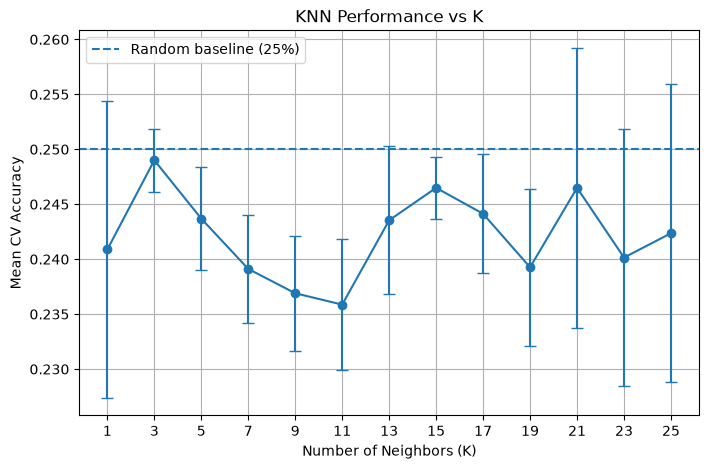

In [44]:
import matplotlib.pyplot as plt

k_values_plot = [
    result["k"]
    for result in cv_results
]

mean_scores = [
    result["mean_accuracy"]
    for result in cv_results
]

std_scores = [
    result["std_accuracy"]
    for result in cv_results
]

plt.figure(figsize=(8, 5))

plt.errorbar(
    k_values_plot,
    mean_scores,
    yerr=std_scores,
    marker="o",
    capsize=4
)

plt.axhline(
    0.25,
    linestyle="--",
    label="Random baseline (25%)"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("KNN Performance vs K")
plt.xticks(k_values_plot)
plt.legend()
plt.grid(True)

plt.show()

In [45]:
results_summary = {
    "Unscaled KNN (K=5)": baseline_accuracy,
    "Standardized KNN (K=5)": standard_accuracy,
    "MinMax KNN (K=5)": minmax_accuracy,
    "GridSearchCV KNN": test_accuracy_grid
}

for model, accuracy in results_summary.items():
    print(f"{model:<30} {accuracy:.4f}")

Unscaled KNN (K=5)             0.2409
Standardized KNN (K=5)         0.2532
MinMax KNN (K=5)               0.2491
GridSearchCV KNN               0.2556


In [ ]:
''' KNN with text description

Can the actual textual content of a support ticket help KNN predict its priority?

We'll use TF-IDF to convert text into numerical vectors.
Why TF-IDF?
Suppose we have:
Ticket 1:
"Unable to login to my account"

Ticket 2:
"Unable to login after changing my password"

Ticket 3:
"Payment failed and money was deducted"

A raw word-count representation would simply count words.
TF-IDF instead gives more importance to words that are useful for distinguishing documents while reducing the influence of extremely common words.
'''

In [48]:
X_text_train = df.loc[X_train.index, "Ticket Description"]
X_text_test = df.loc[X_test.index, "Ticket Description"]

print("Training documents:", len(X_text_train))
print("Test documents:", len(X_text_test))

Training documents: 6775
Test documents: 1694


In [49]:
print("Missing training descriptions:", X_text_train.isna().sum())
print("Missing test descriptions:", X_text_test.isna().sum())

Missing training descriptions: 0
Missing test descriptions: 0


In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

text_knn_pipeline = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english"
            )
        ),
        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=5,
                metric="cosine",
                weights="uniform"
            )
        )
    ]
)

In [51]:
text_knn_pipeline.fit(
    X_text_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['Critical','High','Low','Medium']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character norm

In [52]:
y_pred_text = text_knn_pipeline.predict(
    X_text_test
)

In [53]:
text_accuracy = accuracy_score(
    y_test,
    y_pred_text
)

print("TF-IDF + KNN accuracy:", text_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_text
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_text
    )
)

TF-IDF + KNN accuracy: 0.2644628099173554

Classification Report:
              precision    recall  f1-score   support

    Critical       0.27      0.40      0.32       426
        High       0.26      0.22      0.24       417
         Low       0.25      0.24      0.25       413
      Medium       0.28      0.19      0.23       438

    accuracy                           0.26      1694
   macro avg       0.27      0.26      0.26      1694
weighted avg       0.27      0.26      0.26      1694


Confusion Matrix:
[[170  78 101  77]
 [155  93 102  67]
 [153  86 100  74]
 [159  98  96  85]]


In [54]:
# tuning TF-IDF+KNN

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

text_knn_pipeline = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english"
            )
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ]
)

In [55]:
text_param_grid = {
    "tfidf__ngram_range": [
        (1, 1),
        (1, 2)
    ],
    "tfidf__min_df": [
        1,
        2,
        5
    ],
    "knn__n_neighbors": [
        1,
        3,
        5,
        7,
        9
    ],
    "knn__metric": [
        "cosine",
        "euclidean"
    ],
    "knn__weights": [
        "uniform",
        "distance"
    ]
}

In [56]:
text_grid_search = GridSearchCV(
    estimator=text_knn_pipeline,
    param_grid=text_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

text_grid_search.fit(
    X_text_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__metric': ['cosine', 'euclidean'], 'knn__n_neighbors': [1, 3, ...], 'knn__weights': ['uniform', 'distance'], 'tfidf__min_df': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will on

In [57]:
print("Best CV accuracy:", text_grid_search.best_score_)

print("\nBest parameters:")
print(text_grid_search.best_params_)

Best CV accuracy: 0.25845018450184504

Best parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__weights': 'distance', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}


In [58]:
best_text_knn = text_grid_search.best_estimator_

y_pred_best_text = best_text_knn.predict(
    X_text_test
)

best_text_test_accuracy = accuracy_score(
    y_test,
    y_pred_best_text
)

print("Best TF-IDF + KNN test accuracy:", best_text_test_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best_text
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_best_text
    )
)

Best TF-IDF + KNN test accuracy: 0.2502951593860685

Classification Report:
              precision    recall  f1-score   support

    Critical       0.24      0.35      0.29       426
        High       0.25      0.17      0.20       417
         Low       0.26      0.24      0.25       413
      Medium       0.25      0.24      0.24       438

    accuracy                           0.25      1694
   macro avg       0.25      0.25      0.25      1694
weighted avg       0.25      0.25      0.25      1694


Confusion Matrix:
[[148  73 105 100]
 [151  72  85 109]
 [150  65 100  98]
 [160  78  96 104]]


In [ ]:
'''

                Structured features
                │
                ├── Unscaled KNN        → 24.09%
                │
                ├── StandardScaler      → 25.32%
                │
                ├── MinMaxScaler        → 24.91%
                │
                └── GridSearchCV        → 25.56%
                
                Ticket Description
                │
                ├── TF-IDF + KNN        → 26.45%
                │
                └── Tuned TF-IDF + KNN  → 25.03%

Neither structured metadata nor ticket description alone allows KNN to predict Ticket Priority substantially better than chance.
It could depend on both.


                                 X
                                 │
                  ┌──────────────┴──────────────┐
                  │                             │
                  ▼                             ▼
        Structured features             Ticket Description
                  │                             │
                  ▼                             ▼
        OneHot + StandardScaler              TF-IDF
                  │                             │
                  └──────────────┬──────────────┘
                                 ▼
                          Combined vector
                                 │
                                 ▼
                                KNN

'''

In [59]:
# Build a combined ColumnTransformer
# We'll use:
# - structured categorical features → One-Hot Encoding
# - Customer Age → StandardScaler
# - Ticket Description → TF-IDF

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

combined_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "text",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english"
            ),
            "Ticket Description"
        )
    ]
)

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

combined_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            combined_preprocessor
        ),
        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=5,
                metric="cosine",
                weights="uniform"
            )
        )
    ]
)

In [61]:
combined_pipeline.fit(
    X_train.assign(
        **{
            "Ticket Description": df.loc[
                X_train.index,
                "Ticket Description"
            ]
        }
    ),
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['Critical','High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Customer Age','Customer Gender','Product Purchased',...,'Ticket Subject', 'Ticket Channel','Ticket Description']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolu

In [62]:
X_combined = df[
    [
        "Customer Age",
        "Customer Gender",
        "Product Purchased",
        "Ticket Type",
        "Ticket Subject",
        "Ticket Channel",
        "Ticket Description"
    ]
].copy()

In [63]:
X_combined_train = X_combined.loc[X_train.index]
X_combined_test = X_combined.loc[X_test.index]

print("Training shape:", X_combined_train.shape)
print("Test shape:", X_combined_test.shape)

Training shape: (6775, 7)
Test shape: (1694, 7)


In [64]:
combined_pipeline.fit(
    X_combined_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['Critical','High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Customer Age','Customer Gender','Product Purchased',...,'Ticket Subject', 'Ticket Channel','Ticket Description']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolu

In [65]:
y_pred_combined = combined_pipeline.predict(
    X_combined_test
)

In [66]:
combined_accuracy = accuracy_score(
    y_test,
    y_pred_combined
)

print("Combined KNN accuracy:", combined_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_combined
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_combined
    )
)

Combined KNN accuracy: 0.2550177095631641

Classification Report:
              precision    recall  f1-score   support

    Critical       0.26      0.33      0.29       426
        High       0.25      0.29      0.27       417
         Low       0.24      0.21      0.22       413
      Medium       0.27      0.20      0.23       438

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.25      1694
weighted avg       0.26      0.26      0.25      1694


Confusion Matrix:
[[141 120  88  77]
 [135 119  85  78]
 [141 114  86  72]
 [135 119  98  86]]


In [ ]:
'''

        The Ticket Description contains more useful information for this KNN representation than the structured features do.

        But when we combine everything, the structured features don't provide enough additional useful signal to improve the nearest-neighbor relationships.

    This is particularly interesting for KNN because it doesn't simply "learn which features are important" like a tree-based model might.
KNN asks: Which training points are closest to this point?
When we combine text and structured features, we are changing the geometry of the feature space.
For two customers, the distance becomes something conceptually like
d(x_i,x_j)=text distance + structured-feature distance.
If the structured component contains mostly weak information, it can actually disturb the useful text-based neighborhoods.

'''



'''
        Categorical features
                +
        Customer Age
                +
        TF-IDF representation
                ↓
        KNN distance

But TF-IDF can contain hundreds or thousands of dimensions, while our structured portion contains relatively few dimensions.
So we shouldn't immediately conclude:
"Structured features are useless."

Instead, we should ask:
Are the structured features being given an appropriate amount of influence relative to the text features?

This leads to a very good next experiment: feature/block weighting.



So we now try to move from:
"Which K should I use?"

to the more interesting question:
"How does the representation of the data affect the geometry used by KNN?"
'''

In [67]:
# Create the two feature blocks

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# ---------------------------------------------------------
# 1. Define structured features
# ---------------------------------------------------------

categorical_features = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Channel"
]

numerical_features = [
    "Customer Age"
]

# ---------------------------------------------------------
# 2. Structured preprocessing
# ---------------------------------------------------------

structured_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Fit ONLY on training data
X_structured_train = structured_preprocessor.fit_transform(
    X_combined_train
)

X_structured_test = structured_preprocessor.transform(
    X_combined_test
)

print("Structured train shape:", X_structured_train.shape)
print("Structured test shape:", X_structured_test.shape)

# ---------------------------------------------------------
# 3. TF-IDF preprocessing
# ---------------------------------------------------------

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_text_train_matrix = tfidf.fit_transform(
    X_combined_train["Ticket Description"]
)

X_text_test_matrix = tfidf.transform(
    X_combined_test["Ticket Description"]
)

print("Text train shape:", X_text_train_matrix.shape)
print("Text test shape:", X_text_test_matrix.shape)

Structured train shape: (6775, 71)
Structured test shape: (1694, 71)
Text train shape: (6775, 6095)
Text test shape: (1694, 6095)


In [68]:
# Combine them with different text weights

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

text_weights = [0.25, 0.5, 1.0, 2.0, 4.0]

weight_results = []

for weight in text_weights:

    # Scale the entire text feature block
    X_train_weighted = hstack([
        X_structured_train,
        X_text_train_matrix * weight
    ])

    X_test_weighted = hstack([
        X_structured_test,
        X_text_test_matrix * weight
    ])

    # KNN configuration from our best simple text experiment
    knn = KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        weights="uniform"
    )

    knn.fit(X_train_weighted, y_train)

    y_pred = knn.predict(X_test_weighted)

    accuracy = accuracy_score(y_test, y_pred)

    weight_results.append({
        "text_weight": weight,
        "accuracy": accuracy
    })

    print(f"Text weight = {weight:<4} | Accuracy = {accuracy:.4f}")

Text weight = 0.25 | Accuracy = 0.2544
Text weight = 0.5  | Accuracy = 0.2515
Text weight = 1.0  | Accuracy = 0.2550
Text weight = 2.0  | Accuracy = 0.2379
Text weight = 4.0  | Accuracy = 0.2462


In [69]:
weight_results_df = pd.DataFrame(weight_results)

weight_results_df

,text_weight,accuracy
0,0.25,0.254427
1,0.50,0.251476
2,1.00,0.255018
3,2.00,0.237898
4,4.00,0.246163


In [70]:
best_weight = weight_results_df.loc[
    weight_results_df["accuracy"].idxmax()
]

print("Best text weight:")
print(best_weight)

Best text weight:
text_weight    1.000000
accuracy       0.255018
Name: 2, dtype: float64


In [ ]:
'''
1. Scaling matters slightly.
   - 24.09% → 25.32%
2. Changing K helps only slightly.
   - Best structured KNN ≈ 25.56%
3. Text is somewhat more useful than structured features.
   - Simple TF-IDF + KNN = 26.45%
4. Combining the two doesn't help.
   - Combined = 25.50%
5. Increasing text influence doesn't help.
   - Best tested combined weighting = 25.50%
This strongly suggests that the limitation is not primarily KNN hyperparameters.
'''


# Is Ticket Priority actually predictable from the information we are giving KNN?

In [71]:
categorical_analysis_features = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Channel"
]

for feature in categorical_analysis_features:

    print("=" * 70)
    print(feature)
    print("=" * 70)

    table = pd.crosstab(
        df[feature],
        df["Ticket Priority"],
        normalize="index"
    ) * 100

    print(table.round(2))
    print()

Customer Gender
Ticket Priority  Critical   High    Low  Medium
Customer Gender                                
Female              25.18  24.11  25.08   25.63
Male                24.65  24.31  24.17   26.86
Other               25.61  25.50  23.79   25.09

Product Purchased
Ticket Priority                 Critical   High    Low  Medium
Product Purchased                                             
Adobe Photoshop                    26.52  21.55  22.65   29.28
Amazon Echo                        24.43  24.89  25.79   24.89
Amazon Kindle                      24.75  18.69  22.73   33.84
Apple AirPods                      23.94  29.58  22.54   23.94
Asus ROG                           24.06  22.46  29.41   24.06
Autodesk AutoCAD                   30.10  24.49  23.47   21.94
Bose QuietComfort                  21.58  23.68  30.00   24.74
Bose SoundLink Speaker             25.89  28.43  19.80   25.89
Canon DSLR Camera                  30.10  19.42  21.36   29.13
Canon EOS                       

In [ ]:
'''

Our target has four almost equally sized classes: P(Y=c)approx0.25
Therefore, a classifier that has very little useful information will naturally hover around: 25% accuracy.
And that's exactly what we've observed: 24.09%-26.45%
So we're no longer simply dealing with a "bad KNN implementation."
The dataset itself appears to contain weak predictive relationships between the structured features and Ticket Priority.

'''

# Which words or phrases are associated with each priority?

In [72]:
from collections import Counter
import re

def get_words(text_series):
    words = []

    for text in text_series.dropna():

        text = text.lower()

        # Keep alphabetic words
        tokens = re.findall(r"\b[a-zA-Z]+\b", text)

        words.extend(tokens)

    return Counter(words)


for priority in sorted(df["Ticket Priority"].unique()):

    print("=" * 70)
    print(priority)
    print("=" * 70)

    class_text = df.loc[
        df["Ticket Priority"] == priority,
        "Ticket Description"
    ]

    word_counts = get_words(class_text)

    print(word_counts.most_common(20))
    print()

Critical
[('the', 6673), ('i', 5701), ('issue', 2933), ('to', 2690), ('m', 2637), ('my', 2419), ('please', 2228), ('it', 2143), ('with', 2118), ('an', 1827), ('a', 1654), ('having', 1635), ('assist', 1590), ('and', 1566), ('ve', 1533), ('is', 1439), ('you', 1152), ('this', 1112), ('but', 1102), ('on', 940)]

High
[('the', 6463), ('i', 5534), ('issue', 2778), ('to', 2740), ('m', 2494), ('my', 2377), ('it', 2181), ('please', 2135), ('with', 1993), ('a', 1770), ('an', 1736), ('having', 1534), ('and', 1523), ('ve', 1494), ('assist', 1493), ('is', 1461), ('you', 1217), ('this', 1071), ('but', 1056), ('on', 980)]

Low
[('the', 6396), ('i', 5470), ('issue', 2825), ('to', 2616), ('m', 2554), ('my', 2363), ('it', 2143), ('please', 2100), ('with', 2058), ('an', 1817), ('a', 1629), ('having', 1596), ('assist', 1540), ('ve', 1488), ('and', 1389), ('is', 1379), ('you', 1124), ('but', 1072), ('this', 1061), ('on', 982)]

Medium
[('the', 6922), ('i', 5807), ('issue', 2995), ('to', 2774), ('m', 2634),

In [73]:
# Which words are disproportionately associated with one priority class?

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_analysis = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=5
)

X_text_all = tfidf_analysis.fit_transform(
    df["Ticket Description"].fillna("")
)

feature_names = np.array(
    tfidf_analysis.get_feature_names_out()
)

for priority in sorted(df["Ticket Priority"].unique()):

    print("=" * 70)
    print(priority)
    print("=" * 70)

    class_mask = (
        df["Ticket Priority"].values == priority
    )

    # Mean TF-IDF for this class
    mean_tfidf = X_text_all[class_mask].mean(axis=0)

    mean_tfidf = np.asarray(
        mean_tfidf
    ).ravel()

    top_indices = mean_tfidf.argsort()[-20:][::-1]

    for idx in top_indices:
        print(
            f"{feature_names[idx]:25s} "
            f"{mean_tfidf[idx]:.4f}"
        )

    print()

Critical
product_purchased         0.0939
issue                     0.0868
having                    0.0600
assist                    0.0599
ve                        0.0564
product                   0.0397
problem                   0.0332
data                      0.0309
software                  0.0290
account                   0.0268
steps                     0.0261
persists                  0.0240
update                    0.0237
tried                     0.0234
device                    0.0224
help                      0.0222
started                   0.0217
noticed                   0.0215
unable                    0.0209
resolve                   0.0202

High
product_purchased         0.0923
issue                     0.0834
having                    0.0571
assist                    0.0571
ve                        0.0556
product                   0.0365
problem                   0.0365
data                      0.0292
account                   0.0292
software                  0.

In [74]:
for priority in sorted(df["Ticket Priority"].unique()):

    print("=" * 80)
    print(f"PRIORITY: {priority}")
    print("=" * 80)

    samples = df.loc[
        df["Ticket Priority"] == priority,
        "Ticket Description"
    ].dropna().sample(
        5,
        random_state=42
    )

    for i, text in enumerate(samples, 1):
        print(f"\n{i}. {text}")

    print()

PRIORITY: Critical

1. I'm having an issue with the {product_purchased}. Please assist. Please help me.

I'm having an issue with the {product_purchased}. Please assist. Please help me.

I'm having an I've recently updated the firmware of my {product_purchased}, and the issue started happening afterward. Could it be related to the update?

2. I'm having an issue with the {product_purchased}. Please assist.

Click here to contact us. I'm not sure if this issue is specific to my device or if others have reported similar problems.

3. I'm having an issue with the {product_purchased}. Please assist.

2.4.1.1 As of the 3-5 minutes after receiving your shipment from the shipping company, a confirmation email from the company. It I've noticed that the issue occurs consistently when I use a specific feature or application on my {product_purchased}.

4. I'm having an issue with the {product_purchased}. Please assist.

4. Change the item ID to $3


This is so many places I've been, or were doing

In [79]:
'''
data cleaning
'''

import re

# improving the cleaning text function

import re

def clean_ticket_text(text):

    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Remove HTML tags
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    # Remove placeholder tokens
    text = re.sub(
        r"\{[^}]+\}",
        " ",
        text
    )

    # Remove email addresses
    text = re.sub(
        r"\S+@\S+",
        " ",
        text
    )

    # Preserve contractions by removing apostrophes
    # Example:
    # "I'm" -> "im"
    # "I've" -> "ive"
    # "doesn't" -> "doesnt"
    text = text.replace("'", "")

    # Remove remaining non-alphabetic characters
    text = re.sub(
        r"[^a-z\s]",
        " ",
        text
    )

    # Remove extra whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [80]:
df["Cleaned Ticket Description"] = (
    df["Ticket Description"]
    .apply(clean_ticket_text)
)

In [81]:
for i in range(5):

    original = df["Ticket Description"].iloc[i]
    cleaned = df["Cleaned Ticket Description"].iloc[i]

    print("=" * 80)
    print("ORIGINAL:")
    print(original)

    print("\nCLEANED:")
    print(cleaned)

ORIGINAL:
I'm having an issue with the {product_purchased}. Please assist.

Your billing zip code is: 71701.

We appreciate that you have requested a website address.

Please double check your email address. I've tried troubleshooting steps mentioned in the user manual, but the issue persists.

CLEANED:
im having an issue with the please assist your billing zip code is we appreciate that you have requested a website address please double check your email address ive tried troubleshooting steps mentioned in the user manual but the issue persists
ORIGINAL:
I'm having an issue with the {product_purchased}. Please assist.

If you need to change an existing product.

I'm having an issue with the {product_purchased}. Please assist.

If The issue I'm facing is intermittent. Sometimes it works fine, but other times it acts up unexpectedly.

CLEANED:
im having an issue with the please assist if you need to change an existing product im having an issue with the please assist if the issue im faci

In [82]:
X_clean_train = df.loc[
    X_train.index,
    "Cleaned Ticket Description"
]

X_clean_test = df.loc[
    X_test.index,
    "Cleaned Ticket Description"
]

print("Training samples:", len(X_clean_train))
print("Test samples:", len(X_clean_test))

Training samples: 6775
Test samples: 1694


In [83]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

clean_text_knn_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=False,
            stop_words="english"
        )
    ),
    (
        "knn",
        KNeighborsClassifier(
            n_neighbors=5,
            metric="cosine",
            weights="uniform"
        )
    )
])

In [84]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

clean_text_knn_pipeline.fit(
    X_clean_train,
    y_train
)

y_pred_clean = clean_text_knn_pipeline.predict(
    X_clean_test
)

clean_accuracy = accuracy_score(
    y_test,
    y_pred_clean
)

print("Cleaned Text KNN Accuracy:", clean_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_clean
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_clean
    )
)

Cleaned Text KNN Accuracy: 0.23258559622195984

Classification Report:
              precision    recall  f1-score   support

    Critical       0.22      0.34      0.27       426
        High       0.24      0.21      0.22       417
         Low       0.22      0.19      0.20       413
      Medium       0.26      0.19      0.22       438

    accuracy                           0.23      1694
   macro avg       0.24      0.23      0.23      1694
weighted avg       0.24      0.23      0.23      1694


Confusion Matrix:
[[146  93  88  99]
 [172  86  91  68]
 [167  96  78  72]
 [166  83 105  84]]


In [85]:
''' trying logistic regression and multinomial naive bayes'''

X_text_train = df.loc[
    X_train.index,
    "Ticket Description"
]

X_text_test = df.loc[
    X_test.index,
    "Ticket Description"
]

In [86]:
print("Training samples:", len(X_text_train))
print("Test samples:", len(X_text_test))

Training samples: 6775
Test samples: 1694


In [87]:
#  a TF-IDF + Logistic Regression pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

logistic_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english"
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [ ]:
'''
        Training data
             ↓
        TF-IDF fit
             ↓
        Logistic Regression fit


        Test data
             ↓
        existing TF-IDF transformation
             ↓
        Logistic Regression prediction

'''

In [88]:
logistic_pipeline.fit(
    X_text_train,
    y_train
)

y_pred_logistic = logistic_pipeline.predict(
    X_text_test
)

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("TF-IDF + Logistic Regression Accuracy:")
print(logistic_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_logistic
    )
)

TF-IDF + Logistic Regression Accuracy:
0.2632821723730815

Classification Report:
              precision    recall  f1-score   support

    Critical       0.27      0.28      0.27       426
        High       0.28      0.25      0.27       417
         Low       0.24      0.23      0.23       413
      Medium       0.27      0.29      0.28       438

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.26      1694
weighted avg       0.26      0.26      0.26      1694


Confusion Matrix:
[[118  85 107 116]
 [108 106 102 101]
 [ 98  98  96 121]
 [119  93 100 126]]


In [89]:
nb_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english"
        )
    ),
    (
        "classifier",
        MultinomialNB()
    )
])

In [90]:
nb_pipeline.fit(
    X_text_train,
    y_train
)

y_pred_nb = nb_pipeline.predict(
    X_text_test
)

nb_accuracy = accuracy_score(
    y_test,
    y_pred_nb
)

print("TF-IDF + Multinomial Naive Bayes Accuracy:")
print(nb_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_nb
    )
)

TF-IDF + Multinomial Naive Bayes Accuracy:
0.26741440377804016

Classification Report:
              precision    recall  f1-score   support

    Critical       0.27      0.29      0.28       426
        High       0.26      0.19      0.22       417
         Low       0.25      0.18      0.21       413
      Medium       0.28      0.40      0.33       438

    accuracy                           0.27      1694
   macro avg       0.26      0.27      0.26      1694
weighted avg       0.26      0.27      0.26      1694


Confusion Matrix:
[[122  67  74 163]
 [116  81  77 143]
 [100  87  74 152]
 [107  79  76 176]]


In [91]:
comparison = pd.DataFrame({
    "Model": [
        "KNN",
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        0.2644628099173554,
        logistic_accuracy,
        nb_accuracy
    ]
})

comparison

,Model,Accuracy
0,KNN,0.264463
1,Logistic Regression,0.263282
2,Multinomial Naive Bayes,0.267414


In [ ]:
''' The ticket descriptions contain very weak information for predicting Ticket Priority.'''

''' Does Ticket Priority have a relationship with the other available variables that we excluded?'''


In [92]:
#  dataset auditing

pd.crosstab(
    df["Ticket Status"],
    df["Ticket Priority"],
    normalize="index"
).round(3)

pd.crosstab(
    df["Ticket Status"],
    df["Ticket Priority"]
)

Ticket Priority,Critical,High,Low,Medium
Ticket Status,,,,
Closed,726,705,644,694
Open,692,704,696,727
Pending Customer Response,711,676,723,771


In [93]:
subject_priority = pd.crosstab(
    df["Ticket Subject"],
    df["Ticket Priority"],
    normalize="index"
).round(3)

subject_priority

Ticket Priority,Critical,High,Low,Medium
Ticket Subject,,,,
Account access,0.222,0.255,0.257,0.265
Battery life,0.229,0.247,0.245,0.279
Cancellation request,0.259,0.242,0.244,0.255
Data loss,0.261,0.261,0.224,0.255
Delivery problem,0.226,0.267,0.228,0.278
Display issue,0.251,0.253,0.234,0.262
Hardware issue,0.283,0.238,0.278,0.201
Installation support,0.243,0.268,0.243,0.245
Network problem,0.263,0.243,0.241,0.252


In [94]:
subject_counts = pd.crosstab(
    df["Ticket Subject"],
    df["Ticket Priority"]
)

subject_counts

Ticket Priority,Critical,High,Low,Medium
Ticket Subject,,,,
Account access,113,130,131,135
Battery life,124,134,133,151
Cancellation request,126,118,119,124
Data loss,128,128,110,125
Delivery problem,127,150,128,156
Display issue,120,121,112,125
Hardware issue,155,130,152,110
Installation support,129,142,129,130
Network problem,142,131,130,136


In [ ]:
'''
Our question is:
Is Ticket Subject statistically associated with Ticket Priority, or could these differences reasonably occur from random variation?

The hypotheses are:
H_0:Ticket Subject and Ticket Priority are independent
H_1: Ticket Subject and Ticket Priority are associated

'''



In [95]:
from scipy.stats import chi2_contingency

subject_table = pd.crosstab(
    df["Ticket Subject"],
    df["Ticket Priority"]
)

chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    subject_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", degrees_of_freedom)
print("p-value:", p_value)

Chi-square statistic: 40.85780711849235
Degrees of freedom: 45
p-value: 0.6479874261051508


In [96]:
n = subject_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            subject_table.shape[0] - 1,
            subject_table.shape[1] - 1
        )
    )
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.04010151988951567


In [ ]:
'''

| Investigation | Result |
|---|---|
| Class distribution | Almost perfectly balanced |
| Ticket Status → Priority | Nearly 25% each |
| Ticket Subject → Priority | No significant association |
| Cramér's V | 0.040 — extremely weak |
| Structured KNN | ~24–26% |
| Raw TF-IDF KNN | 26.45% |
| Logistic Regression | 26.33% |
| Naive Bayes | 26.74% |
| Cleaned TF-IDF KNN | 23.26% |

'''


'''
How do K, distance metric, and neighbor weighting affect KNN on our structured ticket features?
'''

In [97]:
# structured KNN pipeline
# Using:
    # - categorical features → One-Hot Encoding
    # - Customer Age → StandardScaler
    # - KNN → classifier

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

categorical_features = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Channel"
]

numerical_features = [
    "Customer Age"
]

structured_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

structured_knn_pipeline = Pipeline([
    (
        "preprocessor",
        structured_preprocessor
    ),
    (
        "knn",
        KNeighborsClassifier()
    )
])

In [98]:
#  we will try different K values, different distance methods and weighting
# K=1, 3, 5, 7, 9, 11, 15, 21, 3

# Distance
    # euclidean
    # manhattan

# Weighting
    # uniform
    # distance

from sklearn.model_selection import GridSearchCV

param_grid = {
    "knn__n_neighbors": [
        1, 3, 5, 7, 9, 11, 15, 21, 31
    ],
    "knn__metric": [
        "euclidean",
        "manhattan"
    ],
    "knn__weights": [
        "uniform",
        "distance"
    ]
}

grid_search_structured = GridSearchCV(
    estimator=structured_knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

In [99]:
grid_search_structured.fit(
    X_train,
    y_train
)

print("Best CV Accuracy:")
print(grid_search_structured.best_score_)

print("\nBest Parameters:")
print(grid_search_structured.best_params_)

Best CV Accuracy:
0.2503321033210332

Best Parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}


In [100]:
results = pd.DataFrame(
    grid_search_structured.cv_results_
)

results[
    [
        "param_knn__n_neighbors",
        "param_knn__metric",
        "param_knn__weights",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
].sort_values(
    "mean_test_score",
    ascending=False
).head(20)

,param_knn__n_neighbors,param_knn__metric,param_knn__weights,mean_test_score,std_test_score,mean_train_score
2,3,euclidean,uniform,0.250332,0.004606,0.552362
16,31,euclidean,uniform,0.250332,0.013920,0.334502
20,3,manhattan,uniform,0.249889,0.003385,0.552915
34,31,manhattan,uniform,0.248118,0.013263,0.335314
14,21,euclidean,uniform,0.247085,0.009728,0.358524
17,31,euclidean,distance,0.246937,0.006709,0.998635
32,21,manhattan,uniform,0.246494,0.006970,0.361181
23,5,manhattan,distance,0.245166,0.004133,0.998635
12,15,euclidean,uniform,0.244576,0.003220,0.377675
6,7,euclidean,uniform,0.244133,0.005227,0.444908


In [101]:
k_results = (
    results
    .groupby("param_knn__n_neighbors")["mean_test_score"]
    .mean()
    .reset_index()
)

k_results

,param_knn__n_neighbors,mean_test_score
0,1,0.241624
1,3,0.245203
2,5,0.242214
3,7,0.239373
4,9,0.238856
5,11,0.236716
6,15,0.240517
7,21,0.244502
8,31,0.247196


In [102]:
metric_results = (
    results
    .groupby("param_knn__metric")["mean_test_score"]
    .agg(["mean", "std"])
    .reset_index()
)

metric_results

,param_knn__metric,mean,std
0,euclidean,0.242304,0.004553
1,manhattan,0.241296,0.004326


In [103]:
weight_results = (
    results
    .groupby("param_knn__weights")["mean_test_score"]
    .agg(["mean", "std"])
    .reset_index()
)

weight_results

,param_knn__weights,mean,std
0,distance,0.240615,0.003309
1,uniform,0.242985,0.005104


In [104]:
# Subject-only train/test data

X_subject = df[["Ticket Subject"]].copy()

X_subject_train = X_subject.loc[X_train.index]
X_subject_test = X_subject.loc[X_test.index]

print("Training shape:", X_subject_train.shape)
print("Test shape:", X_subject_test.shape)

Training shape: (6775, 1)
Test shape: (1694, 1)


In [105]:
# subject-only KNN pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

subject_preprocessor = ColumnTransformer(
    transformers=[
        (
            "subject",
            OneHotEncoder(handle_unknown="ignore"),
            ["Ticket Subject"]
        )
    ]
)

subject_knn_pipeline = Pipeline([
    ("preprocessor", subject_preprocessor),
    ("knn", KNeighborsClassifier())
])

In [106]:
param_grid_subject = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "knn__metric": ["euclidean", "manhattan"],
    "knn__weights": ["uniform", "distance"]
}

In [107]:
subject_grid_search = GridSearchCV(
    estimator=subject_knn_pipeline,
    param_grid=param_grid_subject,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

subject_grid_search.fit(X_subject_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': [1, 3, ...], 'knn__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is s

In [108]:
print("Best CV Accuracy:", subject_grid_search.best_score_)
print("Best Parameters:", subject_grid_search.best_params_)

Best CV Accuracy: 0.25874538745387454
Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}


In [109]:
subject_results = (
    __import__("pandas")
    .DataFrame(subject_grid_search.cv_results_)
    .sort_values("rank_test_score")
)

subject_results[
    [
        "param_knn__n_neighbors",
        "param_knn__metric",
        "param_knn__weights",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score"
    ]
].head(10)

,param_knn__n_neighbors,param_knn__metric,param_knn__weights,mean_test_score,std_test_score,mean_train_score,rank_test_score
3,3,euclidean,distance,0.258745,0.011110,0.253690,1
2,3,euclidean,uniform,0.258745,0.011110,0.253690,1
6,7,euclidean,uniform,0.254022,0.010535,0.255793,3
7,7,euclidean,distance,0.254022,0.010535,0.255793,3
29,11,manhattan,distance,0.254022,0.009939,0.259631,3
28,11,manhattan,uniform,0.254022,0.009939,0.259631,3
5,5,euclidean,distance,0.253432,0.009412,0.250480,7
4,5,euclidean,uniform,0.253432,0.009412,0.250480,7
17,31,euclidean,distance,0.252694,0.015715,0.260258,9
16,31,euclidean,uniform,0.252694,0.015715,0.260258,9


In [110]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred_subject = subject_grid_search.predict(X_subject_test)

subject_test_accuracy = accuracy_score(y_test, y_pred_subject)

print("Subject-only Test Accuracy:", subject_test_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_subject))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_subject))

Subject-only Test Accuracy: 0.24144037780401417

Classification Report:
              precision    recall  f1-score   support

    Critical       0.23      0.29      0.26       426
        High       0.27      0.11      0.16       417
         Low       0.23      0.29      0.26       413
      Medium       0.26      0.27      0.26       438

    accuracy                           0.24      1694
   macro avg       0.25      0.24      0.23      1694
weighted avg       0.25      0.24      0.23      1694


Confusion Matrix:
[[125  54 137 110]
 [130  46 119 122]
 [146  42 121 104]
 [143  31 147 117]]


In [111]:
results = pd.DataFrame({
    "Model": [
        "Structured KNN",
        "Ticket Description KNN",
        "Structured + Description KNN",
        "Ticket Subject KNN"
    ],
    "CV Accuracy": [
        0.2503321033210332,
        0.25845018450184504,
        None,
        0.258745
    ],
    "Test Accuracy": [
        0.25560802833530105,
        0.2644628099173554,
        0.2550177095631641,
        0.24144037780401417
    ]
})

results["Improvement over 25%"] = (
    results["Test Accuracy"] - 0.25
) * 100

results

,Model,CV Accuracy,Test Accuracy,Improvement over 25%
0,Structured KNN,0.250332,0.255608,0.560803
1,Ticket Description KNN,0.258450,0.264463,1.446281
2,Structured + Description KNN,NaN,0.255018,0.501771
3,Ticket Subject KNN,0.258745,0.241440,-0.855962


In [ ]:
'''
        KNN from scratch
              ↓
        Scikit-learn baseline
              ↓
        Feature scaling
              ↓
        K / metric / weighting tuning
              ↓
        Cross-validation + GridSearchCV
              ↓
        Structured features
              ↓
        Text features with TF-IDF
              ↓
        Combined structured + text
              ↓
        Text cleaning
              ↓
        Subject-only controlled experiment
              ↓
        Dataset appears to contain weak predictive signal

'''

In [112]:
# final test split

X_all = df.drop(columns=["Ticket Priority"])
y_all = df["Ticket Priority"]

X_dev, X_final, y_dev, y_final = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=123,
    stratify=y_all
)

print("Development set:", X_dev.shape)
print("Final holdout:", X_final.shape)

print("\nDevelopment class distribution:")
print(y_dev.value_counts(normalize=True))

print("\nFinal holdout class distribution:")
print(y_final.value_counts(normalize=True))

Development set: (6775, 17)
Final holdout: (1694, 17)

Development class distribution:
Ticket Priority
Medium      0.258893
Critical    0.251365
High        0.246199
Low         0.243542
Name: proportion, dtype: float64

Final holdout class distribution:
Ticket Priority
Medium      0.258560
Critical    0.251476
High        0.246163
Low         0.243802
Name: proportion, dtype: float64


In [114]:
X_description_dev = X_dev["Ticket Description"].fillna("")
X_description_final = X_final["Ticket Description"].fillna("")

In [115]:
final_text_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english"
        )
    ),
    (
        "knn",
        KNeighborsClassifier()
    )
])

In [116]:
final_text_param_grid = {
    "tfidf__ngram_range": [
        (1, 1),
        (1, 2)
    ],
    "tfidf__min_df": [
        1,
        2,
        5
    ],
    "knn__n_neighbors": [
        1,
        3,
        5,
        7,
        9
    ],
    "knn__metric": [
        "cosine",
        "euclidean"
    ],
    "knn__weights": [
        "uniform",
        "distance"
    ]
}

In [117]:
final_text_grid = GridSearchCV(
    estimator=final_text_pipeline,
    param_grid=final_text_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

final_text_grid.fit(
    X_description_dev,
    y_dev
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__metric': ['cosine', 'euclidean'], 'knn__n_neighbors': [1, 3, ...], 'knn__weights': ['uniform', 'distance'], 'tfidf__min_df': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will on

In [118]:
print("Best CV Accuracy:")
print(final_text_grid.best_score_)

print("\nBest Parameters:")
print(final_text_grid.best_params_)

Best CV Accuracy:
0.2597785977859779

Best Parameters:
{'knn__metric': 'cosine', 'knn__n_neighbors': 3, 'knn__weights': 'uniform', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


In [119]:
final_cv_results = (
    pd.DataFrame(final_text_grid.cv_results_)
    .sort_values("rank_test_score")
)

final_cv_results[
    [
        "param_tfidf__ngram_range",
        "param_tfidf__min_df",
        "param_knn__n_neighbors",
        "param_knn__metric",
        "param_knn__weights",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score"
    ]
].head(10)

,param_tfidf__ngram_range,param_tfidf__min_df,param_knn__n_neighbors,param_knn__metric,param_knn__weights,mean_test_score,std_test_score,mean_train_score,rank_test_score
13,"(1, 2)",1,3,cosine,uniform,0.259779,0.007990,0.548192,1
73,"(1, 2)",1,3,euclidean,uniform,0.259779,0.007990,0.548192,1
98,"(1, 1)",2,7,euclidean,uniform,0.257712,0.001644,0.448413,3
38,"(1, 1)",2,7,cosine,uniform,0.257712,0.001644,0.448413,3
79,"(1, 2)",1,3,euclidean,distance,0.257712,0.007661,0.958930,5
109,"(1, 2)",1,9,euclidean,uniform,0.257565,0.008218,0.426421,6
49,"(1, 2)",1,9,cosine,uniform,0.257565,0.008218,0.426421,6
19,"(1, 2)",1,3,cosine,distance,0.257269,0.007874,0.958930,8
48,"(1, 1)",1,9,cosine,uniform,0.256974,0.008484,0.427269,9
108,"(1, 1)",1,9,euclidean,uniform,0.256974,0.008484,0.427269,9


In [120]:
# Predict on the untouched final holdout
y_final_pred = final_text_grid.predict(X_description_final)

# Final accuracy
final_accuracy = accuracy_score(y_final, y_final_pred)

print("FINAL HOLDOUT ACCURACY:")
print(final_accuracy)

print("\nFINAL CLASSIFICATION REPORT:")
print(classification_report(y_final, y_final_pred))

print("\nFINAL CONFUSION MATRIX:")
print(confusion_matrix(y_final, y_final_pred))

FINAL HOLDOUT ACCURACY:
0.24970484061393153

FINAL CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Critical       0.24      0.43      0.31       426
        High       0.27      0.22      0.24       417
         Low       0.23      0.18      0.20       413
      Medium       0.27      0.17      0.21       438

    accuracy                           0.25      1694
   macro avg       0.25      0.25      0.24      1694
weighted avg       0.25      0.25      0.24      1694


FINAL CONFUSION MATRIX:
[[183  84  83  76]
 [188  90  76  63]
 [194  81  75  63]
 [197  78  88  75]]


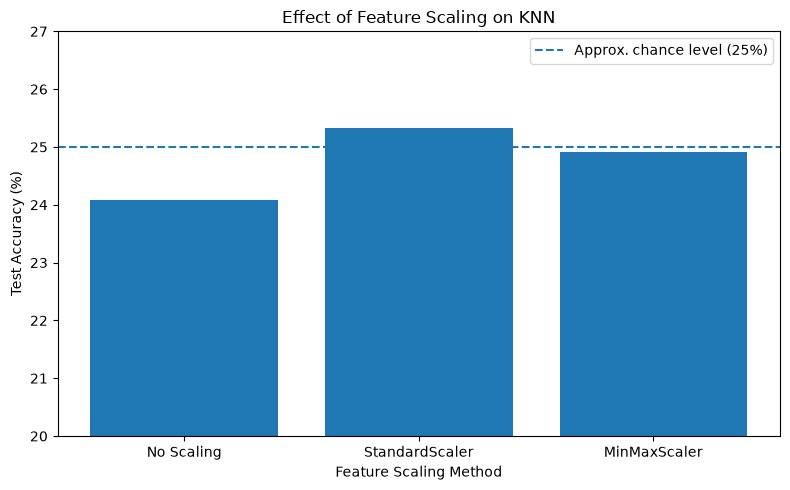

In [122]:


scaling_results = pd.DataFrame({
    "Scaling": [
        "No Scaling",
        "StandardScaler",
        "MinMaxScaler"
    ],
    "Accuracy": [
        0.2408500590318772,
        0.2532467532467532,
        0.24911452184179456
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(
    scaling_results["Scaling"],
    scaling_results["Accuracy"] * 100
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. chance level (25%)"
)

plt.xlabel("Feature Scaling Method")
plt.ylabel("Test Accuracy (%)")
plt.title("Effect of Feature Scaling on KNN")

plt.ylim(20, 27)

plt.legend()
plt.tight_layout()
plt.show()

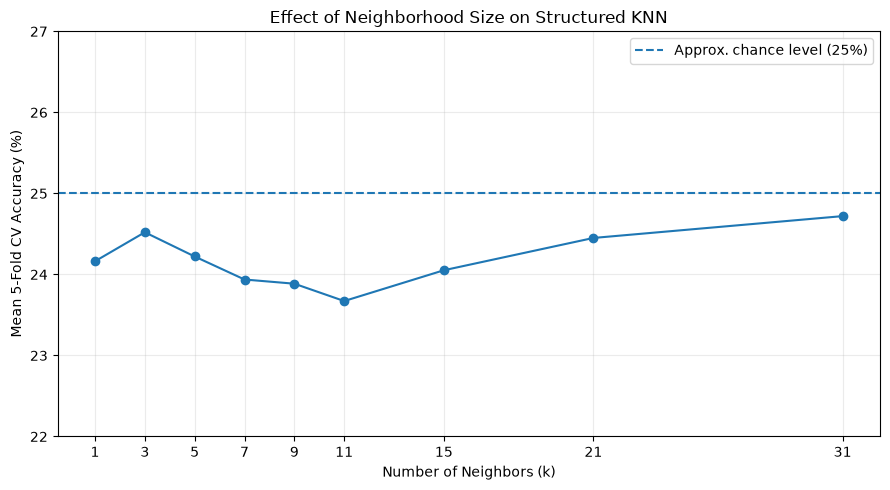

In [123]:
k_values = np.array([
    1, 3, 5, 7, 9, 11, 15, 21, 31
])

k_cv_accuracy = np.array([
    0.241624,
    0.245203,
    0.242214,
    0.239373,
    0.238856,
    0.236716,
    0.240517,
    0.244502,
    0.247196
])

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    k_cv_accuracy * 100,
    marker="o"
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. chance level (25%)"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean 5-Fold CV Accuracy (%)")
plt.title("Effect of Neighborhood Size on Structured KNN")

plt.xticks(k_values)
plt.ylim(22, 27)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

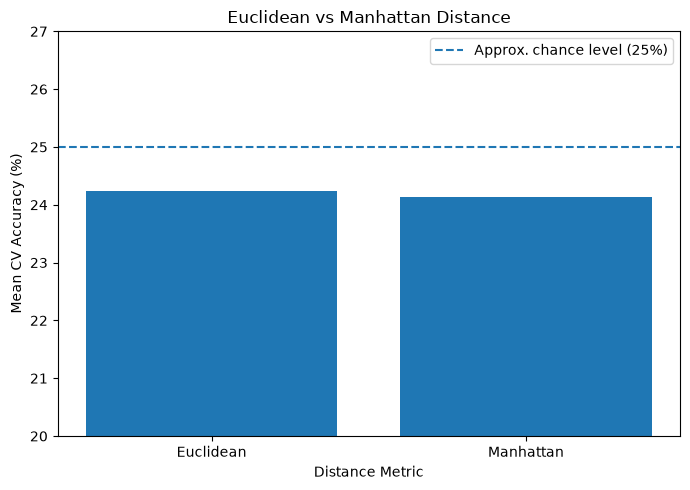

In [124]:
metric_results = pd.DataFrame({
    "Distance Metric": [
        "Euclidean",
        "Manhattan"
    ],
    "Mean CV Accuracy": [
        0.242304,
        0.241296
    ]
})

plt.figure(figsize=(7, 5))

plt.bar(
    metric_results["Distance Metric"],
    metric_results["Mean CV Accuracy"] * 100
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. chance level (25%)"
)

plt.xlabel("Distance Metric")
plt.ylabel("Mean CV Accuracy (%)")
plt.title("Euclidean vs Manhattan Distance")

plt.ylim(20, 27)

plt.legend()
plt.tight_layout()
plt.show()

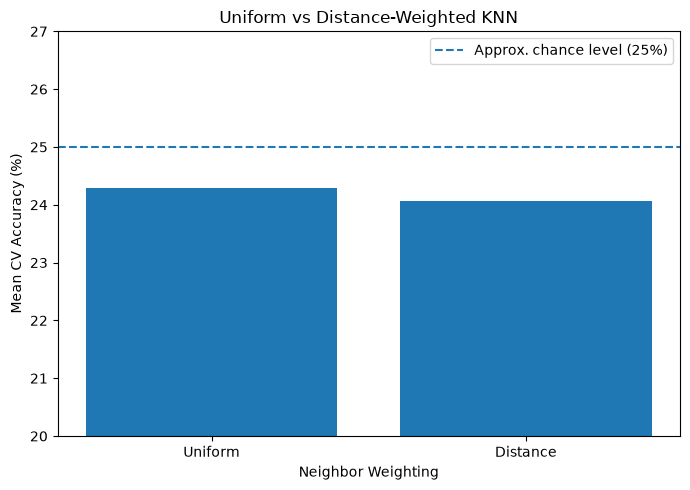

In [125]:
weight_results = pd.DataFrame({
    "Weighting": [
        "Uniform",
        "Distance"
    ],
    "Mean CV Accuracy": [
        0.242985,
        0.240615
    ]
})

plt.figure(figsize=(7, 5))

plt.bar(
    weight_results["Weighting"],
    weight_results["Mean CV Accuracy"] * 100
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. chance level (25%)"
)

plt.xlabel("Neighbor Weighting")
plt.ylabel("Mean CV Accuracy (%)")
plt.title("Uniform vs Distance-Weighted KNN")

plt.ylim(20, 27)

plt.legend()
plt.tight_layout()
plt.show()

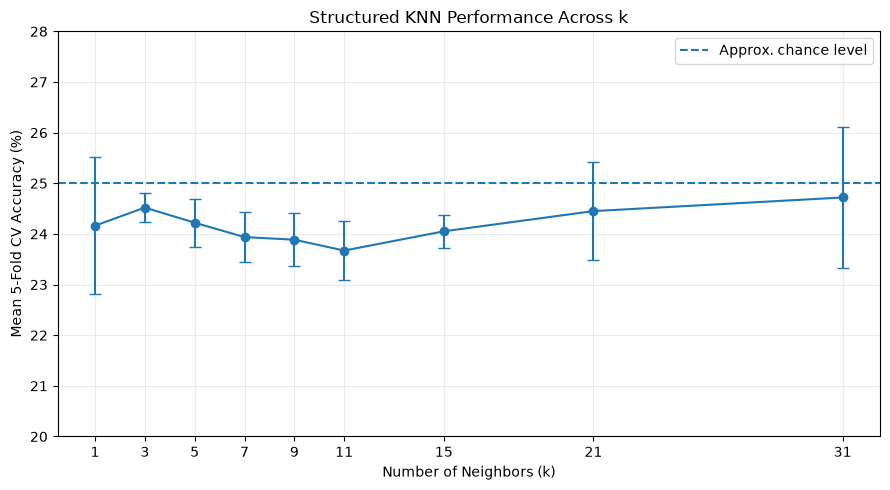

In [126]:
k_values = np.array([
    1, 3, 5, 7, 9, 11, 15, 21, 31
])

k_mean = np.array([
    0.241624,
    0.245203,
    0.242214,
    0.239373,
    0.238856,
    0.236716,
    0.240517,
    0.244502,
    0.247196
])

k_std = np.array([
    0.0135,
    0.0029,
    0.0047,
    0.0049,
    0.0052,
    0.0059,
    0.0032,
    0.0097,
    0.0139
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    k_values,
    k_mean * 100,
    yerr=k_std * 100,
    marker="o",
    capsize=4
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. chance level"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean 5-Fold CV Accuracy (%)")
plt.title("Structured KNN Performance Across k")

plt.xticks(k_values)
plt.ylim(20, 28)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

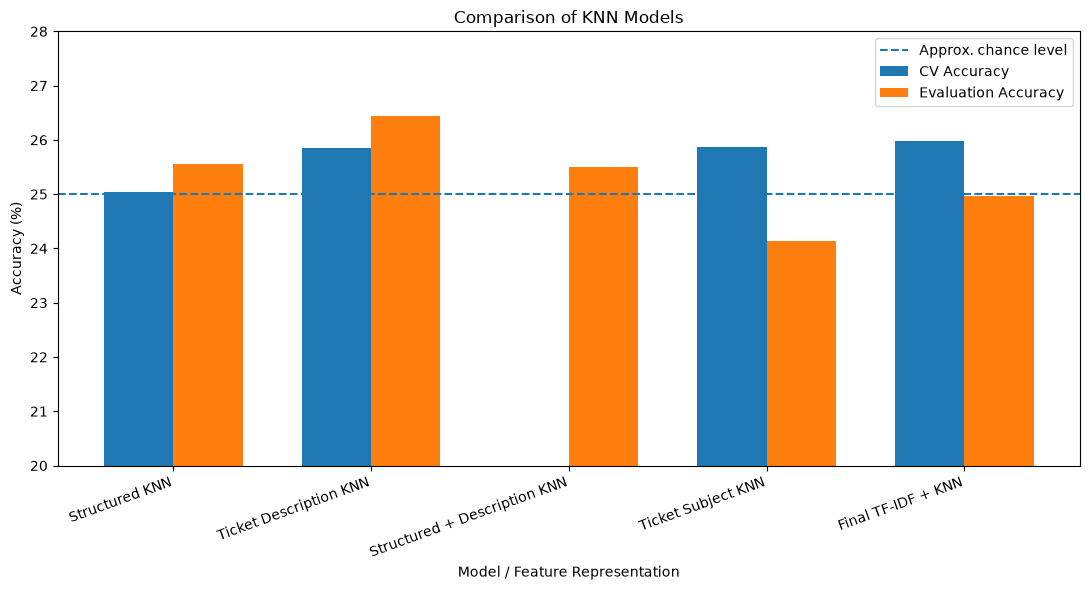

In [127]:
model_results = pd.DataFrame({
    "Model": [
        "Structured KNN",
        "Ticket Description KNN",
        "Structured + Description KNN",
        "Ticket Subject KNN",
        "Final TF-IDF + KNN"
    ],
    "CV Accuracy": [
        0.250332,
        0.258450,
        np.nan,
        0.258745,
        0.259779
    ],
    "Evaluation Accuracy": [
        0.255608,
        0.264463,
        0.255018,
        0.241440,
        0.249705
    ]
})

x = np.arange(len(model_results))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    model_results["CV Accuracy"] * 100,
    width,
    label="CV Accuracy"
)

plt.bar(
    x + width / 2,
    model_results["Evaluation Accuracy"] * 100,
    width,
    label="Evaluation Accuracy"
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. chance level"
)

plt.xlabel("Model / Feature Representation")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of KNN Models")

plt.xticks(
    x,
    model_results["Model"],
    rotation=20,
    ha="right"
)

plt.ylim(20, 28)

plt.legend()

plt.tight_layout()
plt.show()

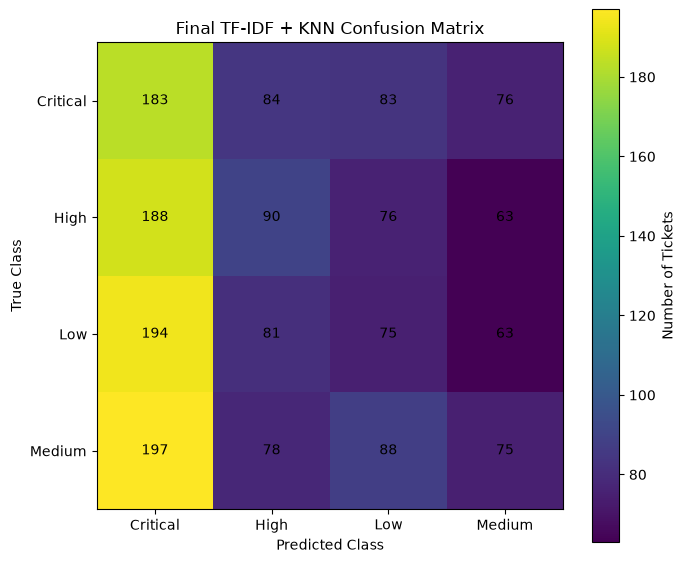

In [128]:
final_cm = np.array([
    [183, 84, 83, 76],
    [188, 90, 76, 63],
    [194, 81, 75, 63],
    [197, 78, 88, 75]
])

classes = [
    "Critical",
    "High",
    "Low",
    "Medium"
]

plt.figure(figsize=(7, 6))

plt.imshow(
    final_cm,
    interpolation="nearest"
)

plt.title("Final TF-IDF + KNN Confusion Matrix")

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    np.arange(len(classes)),
    classes
)

plt.yticks(
    np.arange(len(classes)),
    classes
)

for i in range(final_cm.shape[0]):
    for j in range(final_cm.shape[1]):
        plt.text(
            j,
            i,
            final_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar(
    label="Number of Tickets"
)

plt.tight_layout()
plt.show()

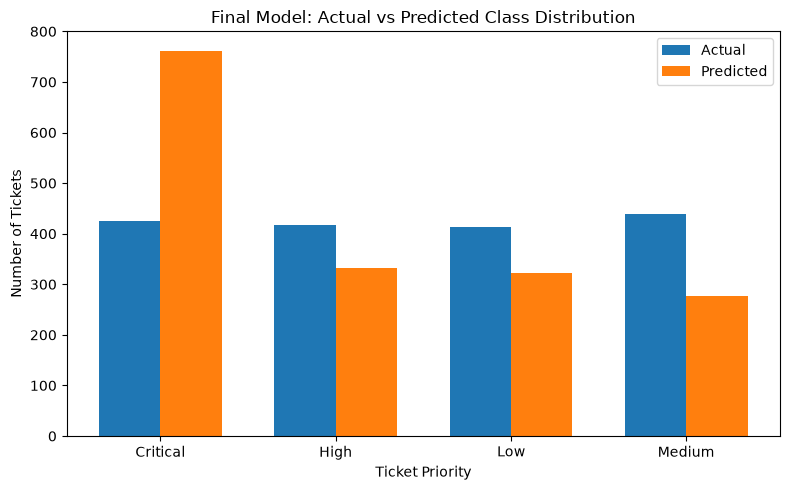

In [129]:
classes = [
    "Critical",
    "High",
    "Low",
    "Medium"
]

actual_counts = np.array([
    426,
    417,
    413,
    438
])

predicted_counts = np.array([
    762,
    333,
    322,
    277
])

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    actual_counts,
    width,
    label="Actual"
)

plt.bar(
    x + width / 2,
    predicted_counts,
    width,
    label="Predicted"
)

plt.xlabel("Ticket Priority")
plt.ylabel("Number of Tickets")
plt.title("Final Model: Actual vs Predicted Class Distribution")

plt.xticks(
    x,
    classes
)

plt.legend()

plt.tight_layout()
plt.show()

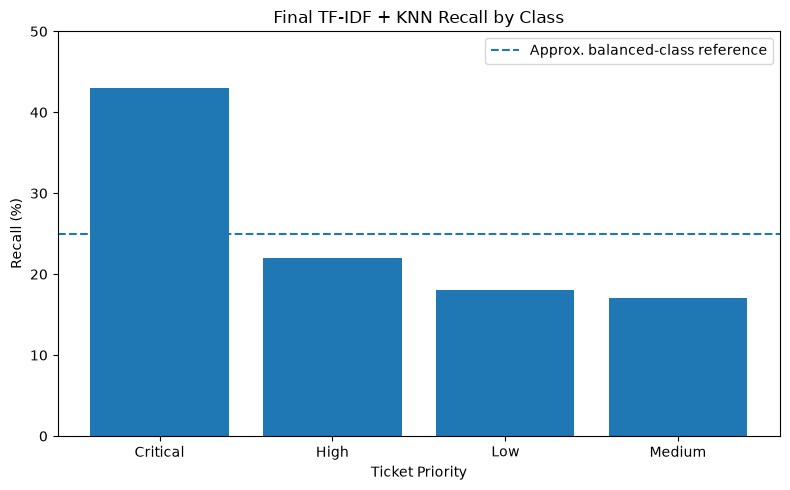

In [130]:
classes = [
    "Critical",
    "High",
    "Low",
    "Medium"
]

recall = np.array([
    0.43,
    0.22,
    0.18,
    0.17
])

plt.figure(figsize=(8, 5))

plt.bar(
    classes,
    recall * 100
)

plt.axhline(
    25,
    linestyle="--",
    label="Approx. balanced-class reference"
)

plt.xlabel("Ticket Priority")
plt.ylabel("Recall (%)")
plt.title("Final TF-IDF + KNN Recall by Class")

plt.ylim(0, 50)

plt.legend()

plt.tight_layout()
plt.show()

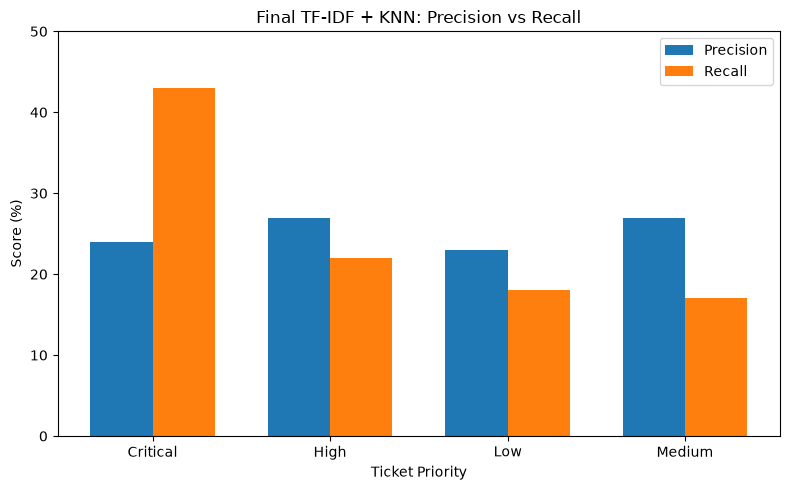

In [132]:
precision = np.array([
    0.24,
    0.27,
    0.23,
    0.27
])

recall = np.array([
    0.43,
    0.22,
    0.18,
    0.17
])

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    precision * 100,
    width,
    label="Precision"
)

plt.bar(
    x + width / 2,
    recall * 100,
    width,
    label="Recall"
)

plt.xlabel("Ticket Priority")
plt.ylabel("Score (%)")
plt.title("Final TF-IDF + KNN: Precision vs Recall")

plt.xticks(
    x,
    classes
)

plt.ylim(0, 50)

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
'''
    Scaling matters
          ↓
    k has limited effect
          ↓
    Different representations still stay near chance
          ↓
    Final model confusion matrix shows poor class separation
          ↓
    Predictions are strongly biased toward Critical
'''

In [133]:
import joblib
from pathlib import Path

# Get the best fitted pipeline from GridSearchCV
final_model = final_text_grid.best_estimator_

# Create a models directory
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save the complete pipeline
model_path = models_dir / "final_tfidf_knn.joblib"

joblib.dump(final_model, model_path)

print(f"Model saved to: {model_path}")

Model saved to: models/final_tfidf_knn.joblib


In [134]:
import joblib

# Load the saved model
loaded_model = joblib.load("models/final_tfidf_knn.joblib")

# Predict using the loaded model
y_final_pred_loaded = loaded_model.predict(X_description_final)

# Check whether predictions are identical
same_predictions = np.array_equal(
    y_final_pred,
    y_final_pred_loaded
)

print("Predictions identical:", same_predictions)

Predictions identical: True


In [135]:
loaded_accuracy = accuracy_score(
    y_final,
    y_final_pred_loaded
)

print("Loaded model accuracy:", loaded_accuracy)

Loaded model accuracy: 0.24970484061393153


In [136]:
print(loaded_model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(ngram_range=(1, 2), stop_words='english')),
                ('knn', KNeighborsClassifier(metric='cosine', n_neighbors=3))])


In [137]:
print("KNN parameters:")
print(loaded_model.named_steps["knn"])

print("\nTF-IDF parameters:")
print(loaded_model.named_steps["tfidf"])

KNN parameters:
KNeighborsClassifier(metric='cosine', n_neighbors=3)

TF-IDF parameters:
TfidfVectorizer(ngram_range=(1, 2), stop_words='english')


In [138]:
new_ticket = [
    "I am having a problem with my device and the issue keeps occurring."
]

prediction = loaded_model.predict(new_ticket)

print("Predicted Ticket Priority:", prediction[0])

Predicted Ticket Priority: High


In [139]:
import json

metadata = {
    "model": "KNN",
    "representation": "TF-IDF Ticket Description",
    "n_neighbors": 3,
    "metric": "cosine",
    "weights": "uniform",
    "ngram_range": [1, 2],
    "min_df": 1,
    "cv_accuracy": 0.2597785977859779,
    "final_holdout_accuracy": 0.24970484061393153,
    "target": "Ticket Priority",
    "classes": [
        "Critical",
        "High",
        "Low",
        "Medium"
    ]
}

with open("models/final_tfidf_knn_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved.")

Metadata saved.


In [ ]:
'''

                            Dataset
                               │
                     ┌─────────┴─────────┐
                     │                   │
               Development            Final Holdout
                 6775                    1694
                     │                   │
               GridSearchCV              │
                     │                   │
               Select model              │
                     │                   │
                     └───────┐           │
                             ↓           │
                        Final Model      │
                             │           │
                             └───────────→ Evaluate

'''